<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/03_hebbian_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 3: Hebbian Learning

Lesson 3 of 8, about 25 minutes.

After this lesson you should be able to:

1. State Hebb's rule and write it as the update $\Delta w = c\, o\, x$.
2. Carry out Hebbian learning by hand and check each step in code.
3. Compare Hebbian learning with discrete (signum) and continuous (sigmoid) neurons.
4. Explain why plain Hebbian learning makes the weights grow without limit.

You will need: lessons 1 and 2, and dot products.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Hebb's rule

Hebb (1949) proposed that when one neuron repeatedly takes part in firing another, the connection
between them gets stronger. For a single artificial neuron this becomes

$$
net = \mathbf{w}^\top \mathbf{x}, \qquad o = f(net), \qquad
\Delta \mathbf{w} = c\, o\, \mathbf{x}
$$

where $c > 0$ is the learning constant. If an input $x_i$ and the output $o$ have the same sign,
$w_i$ goes up. If they have opposite signs, it goes down.

There is no target output anywhere in the rule. The neuron strengthens whatever response it already
gives, which makes Hebbian learning unsupervised.

## Worked example

This example is from Zurada (1992).

| | value |
|---|---|
| initial weights $\mathbf{w}^1$ | $[1,\ -1,\ 0,\ 0.5]$ |
| $\mathbf{x}_1$ | $[1,\ -2,\ 1.5,\ 0]$ |
| $\mathbf{x}_2$ | $[1,\ -0.5,\ -2,\ -1.5]$ |
| $\mathbf{x}_3$ | $[0,\ 1,\ -1,\ 1.5]$ |
| learning constant | $c = 1$, activation $f = \operatorname{sgn}$ |

Step 1: $net^1 = 1\cdot1 + (-1)(-2) + 0\cdot1.5 + 0.5\cdot0 = 3$, so $o = \operatorname{sgn}(3) = 1$
and

$$\mathbf{w}^2 = \mathbf{w}^1 + 1 \cdot 1 \cdot \mathbf{x}_1 = [2,\ -3,\ 1.5,\ 0.5].$$

Work out steps 2 and 3 yourself before running the next cell.

In [2]:
from nnlab.learning_rules import hebbian
from nnlab import activations as act

w0 = [1, -1, 0, 0.5]
X = [[1, -2, 1.5, 0],
     [1, -0.5, -2, -1.5],
     [0, 1, -1, 1.5]]

discrete = hebbian(w0, X, c=1, activation=act.bipolar_step)
discrete.print_steps()

initial w = [ 1.  -1.   0.   0.5]
epoch 1, x1:  net = +3.000  o = +1.000  ->  w = [ 2.  -3.   1.5  0.5]
epoch 1, x2:  net = -0.250  o = -1.000  ->  w = [ 1.  -2.5  3.5  2. ]
epoch 1, x3:  net = -3.000  o = -1.000  ->  w = [ 1.  -3.5  4.5  0.5]


**Steps 2 and 3**

<details><summary>Answer</summary>

Step 2: $net^2 = \mathbf{w}^2 \cdot \mathbf{x}_2 = -0.25$, so $o = -1$ and $\mathbf{w}^3 = \mathbf{w}^2 - \mathbf{x}_2 = [1,\ -2.5,\ 3.5,\ 2]$.

Step 3: $net^3 = -3$, so $o = -1$ and $\mathbf{w}^4 = [1,\ -3.5,\ 4.5,\ 0.5]$.

</details>

## Discrete and continuous neurons

If we replace $\operatorname{sgn}$ with the bipolar sigmoid, the updates become graded. A neuron
that is only weakly active changes its weights only a little.

initial w = [ 1.  -1.   0.   0.5]
epoch 1, x1:  net = +3.000  o = +0.905  ->  w = [ 1.905 -2.81   1.358  0.5  ]
epoch 1, x2:  net = -0.155  o = -0.077  ->  w = [ 1.828 -2.772  1.513  0.616]
epoch 1, x3:  net = -3.360  o = -0.933  ->  w = [ 1.828 -3.704  2.445 -0.783]


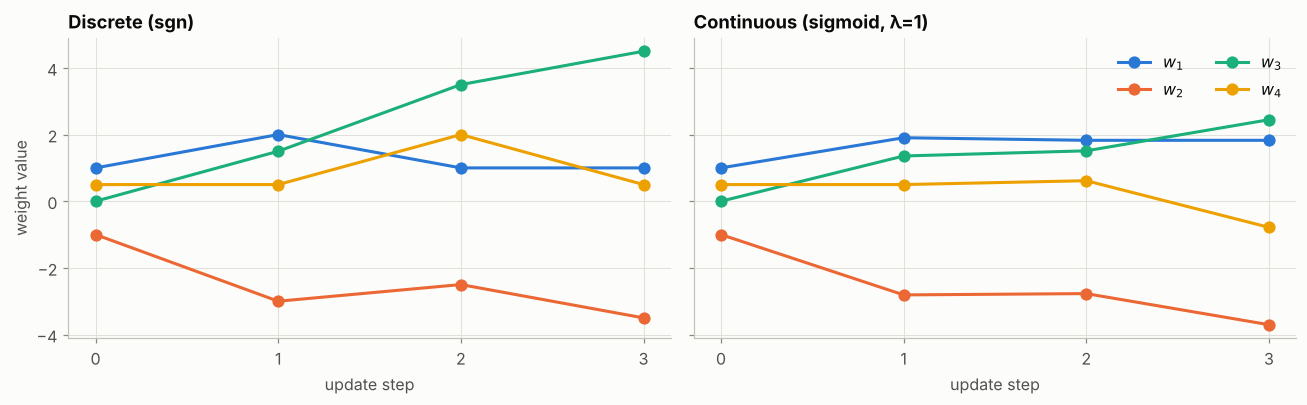

In [3]:
continuous = hebbian(w0, X, c=1, activation=act.bipolar_sigmoid)
continuous.print_steps()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, hist, title in [(axes[0], discrete, "Discrete (sgn)"), (axes[1], continuous, "Continuous (sigmoid, λ=1)")]:
    traj = hist.weight_trajectory()
    for i in range(traj.shape[1]):
        ax.plot(range(len(traj)), traj[:, i], marker="o", label=f"$w_{i + 1}$")
    ax.set(title=title, xlabel="update step", xticks=range(len(traj)))
axes[0].set_ylabel("weight value")
axes[1].legend(ncol=2)
fig.tight_layout()
plt.show()

## Weights that keep growing

Every update adds $c\,o\,\mathbf{x}$. If the same patterns keep coming back, these additions pile
up and $\|\mathbf{w}\|$ keeps growing. Here are the three patterns presented 30 times.

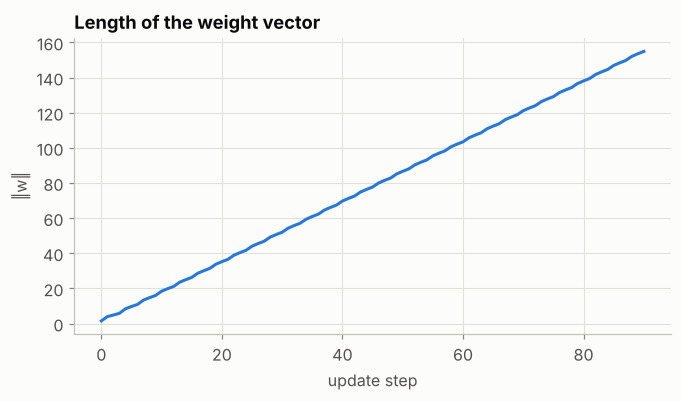

‖w‖ went from 1.50 to 154.93 after 90 updates


In [4]:
long_run = hebbian(w0, X, c=1, activation=act.bipolar_step, epochs=30)
norms = np.linalg.norm(long_run.weight_trajectory(), axis=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(norms, color=PALETTE[0])
ax.set(title="Length of the weight vector", xlabel="update step", ylabel="‖w‖")
plt.show()
print(f"‖w‖ went from {norms[0]:.2f} to {norms[-1]:.2f} after {len(norms) - 1} updates")

In practice something has to hold the weights back. Two common choices are weight decay,
$\Delta\mathbf{w} = c\,o\,\mathbf{x} - \gamma\,\mathbf{w}$, and Oja's rule,
$\Delta\mathbf{w} = c\,o\,(\mathbf{x} - o\,\mathbf{w})$, which keeps the weight vector at roughly
unit length.

## Exercises

1. Set $c = 0.5$ and run the worked example again. Do the final weights simply halve?
2. Add weight decay with $\gamma = 0.1$ and repeat the 30-epoch run. Does $\|\mathbf{w}\|$ level off?

In [5]:
# Exercise 2, starter code
w = np.array(w0, dtype=float)
gamma, c = 0.1, 1.0
norms_decay = [np.linalg.norm(w)]
for epoch in range(30):
    for x in np.asarray(X, dtype=float):
        o = np.sign(w @ x)
        w = w + c * o * x - gamma * w   # Hebbian term plus decay term
        norms_decay.append(np.linalg.norm(w))
print(f"final ‖w‖ with decay: {norms_decay[-1]:.2f}")

final ‖w‖ with decay: 16.85


**Answer to exercise 1**

<details><summary>Answer</summary>

No. After step 1 the weights are $[1.5,\ -2,\ 0.75,\ 0.5]$, and now $net^2 = +0.25$ instead of $-0.25$. The neuron outputs $+1$ for $\mathbf{x}_2$ and the rest of the run goes differently, ending at $[2,\ -2.75,\ 0.25,\ -1]$.

The learning constant scales the updates but not the initial weights, so changing $c$ changes the balance between the starting weights and what has been learned. With a step activation, a small change that flips the sign of one $net$ changes every step after it.

</details>

## Summary

- Hebbian learning strengthens weights whose input agrees with the output: Δw = c·o·x.
- No target output is needed, so the rule is unsupervised.
- With a sigmoid the updates are graded. With a step function they are all or nothing.
- Without decay or normalisation the weights grow without limit.

Next: [Lesson 4, The Perceptron Learning Rule](04_perceptron_learning_rule.ipynb)

### References

- Hebb, D. O. (1949). *The Organization of Behavior: A Neuropsychological Theory*. Wiley.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.